# Chapter 15 — NLP 기반 SQLi/XSS 탐지 (실습)



In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q pandas
# !pip install -q numpy
# !pip install -q scikit-learn

In [2]:
import re
import numpy as np
import pandas as pd
from urllib.parse import unquote
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
rng = np.random.default_rng(42)

In [3]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

---
## Step 1. 합성 CSIC 데이터 생성

In [4]:
# 실무형 데이터셋: 템플릿을 랜덤 파라미터로 '고유화'해 train/test 중복 누수를 없애고,
# 공격 토큰을 품은 '정상 경계 사례'를 섞어 100% 분리(과완벽)를 막는다.
normal_tpl = [
    '/index.jsp?id=', '/search?q=', '/products/list?cat=', '/cart/add?item=',
    '/login?user=', '/profile?uid=', '/comments/page/', '/api/v1/users/',
    '/article/show?id=', '/news?category=', '/order/', '/api/v1/products?page=',
]
sqli_tpl = [
    "/login?id=1' OR 1=1-- ", "/search?q=' UNION SELECT {c} FROM users-- ",
    "/article?id={n}; DROP TABLE users", "/login?user=admin' OR '1'='1",
    "/?id={n} AND 1=2 UNION SELECT password FROM admin",
    "/?id={n} WAITFOR DELAY '0:0:5'", "/login?id=' OR sleep({n})-- ",
    "/?cat={n}' UNION ALL SELECT NULL,NULL,version()-- ",
]
xss_tpl = [
    "/comment?text=<script>alert({n})</script>", "/search?q=<img src=x onerror=alert({n})>",
    "/?name=<svg/onload=alert('{c}')>", "/post?body=javascript:document.cookie",
    "/?html=<iframe src='evil{n}.com'></iframe>", "/c?x=%3Cscript%3Ealert({n})%3C/script%3E",
]
# 공격 토큰을 품었지만 정상인 경계 사례 (오탐 FP 유발)
borderline_tpl = [
    '/search?q=how to select a good {w}', '/products?type=union {w}',
    '/article?title={n} or {n} tips for {w}', '/blog?tag=javascript {w}',
    '/help?q=drop table {w} rules', '/docs?section=onload event in {w}',
    '/forum?topic=script writing for {w}', '/wiki?term=sql {w} basics',
    "/search?q=O'Brien {w}", "/profile?name=D'Angelo", "/comment?text=I <3 {w}",
    '/calc?expr={n} < {n}', '/note?text=use -- to comment in {w} class', '/search?q={w} = best',
]
WORDS = ['laptop','python','security','network','camera','router','guide','course']

def vary(tpl, k):
    out = []
    for _ in range(k):
        s = tpl.format(n=int(rng.integers(1, 10**6)),
                       c=rng.choice(['name','email','pw','id']),
                       w=rng.choice(WORDS))
        sep = '&' if '?' in s else '?'
        out.append(f"{s}{sep}_r={int(rng.integers(1, 10**6))}")   # 고유화 파라미터
    return out

normal_payloads     = [x for t in normal_tpl     for x in vary(t, 120)]   # ~1440
borderline_payloads = [x for t in borderline_tpl for x in vary(t, 20)]    # ~160 (정상)
sqli_payloads       = [x for t in sqli_tpl       for x in vary(t, 40)]    # ~320
xss_payloads        = [x for t in xss_tpl        for x in vary(t, 40)]    # ~240

df = pd.DataFrame({
    'payload': normal_payloads + borderline_payloads + sqli_payloads + xss_payloads,
    'label':   (['normal']*len(normal_payloads) + ['normal']*len(borderline_payloads)
                + ['SQLi']*len(sqli_payloads) + ['XSS']*len(xss_payloads)),
}).drop_duplicates('payload').sample(frac=1, random_state=0).reset_index(drop=True)
df['label_bin'] = (df['label'] != 'normal').astype(int)
# 라벨 노이즈 6% — 실제 데이터셋의 라벨링 오류로 완벽 분리(과완벽)를 막는다
_noise = rng.choice(df.index.to_numpy(), size=int(len(df)*0.06), replace=False)
df.loc[_noise, 'label_bin'] = 1 - df.loc[_noise, 'label_bin']
print(df['label'].value_counts())
df.head()

label
normal    1720
SQLi       320
XSS        240
Name: count, dtype: int64


,payload,label,label_bin
0,/calc?expr=495491 < 495491&_r=564922,normal,0
1,/help?q=drop table python rules&_r=142940,normal,0
2,/?id=84975 AND 1=2 UNION SELECT password FROM ...,SQLi,1
3,/search?q=&_r=802026,normal,0
4,/login?id=' OR sleep(54775)-- &_r=687121,SQLi,1


---
## Step 2. 정규화

In [5]:
def normalize(s: str) -> str:
    for _ in range(3):
        new = unquote(s)
        if new == s: break
        s = new
    s = s.lower()
    s = re.sub(r'\s+', ' ', s)
    return s.strip()

df['payload_norm'] = df['payload'].apply(normalize)
df[['payload', 'payload_norm']].sample(8, random_state=0)

,payload,payload_norm
1677,/order/?_r=174590,/order/?_r=174590
1533,/api/v1/users/?_r=407634,/api/v1/users/?_r=407634
1890,/c?x=%3Cscript%3Ealert(724191)%3C/script%3E&_r...,/c?x=<script>alert(724191)</script>&_r=839937
148,/login?user=&_r=450600,/login?user=&_r=450600
1988,/api/v1/users/?_r=102828,/api/v1/users/?_r=102828
69,/comments/page/?_r=414052,/comments/page/?_r=414052
2226,/article/show?id=&_r=764343,/article/show?id=&_r=764343
156,/login?user=&_r=71756,/login?user=&_r=71756


---
## Step 3. TF-IDF char-ngram + LogReg

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df['payload_norm'], df['label_bin'], test_size=0.3, stratify=df['label_bin'], random_state=42)

pipe_lr = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4), max_features=3000)),
    ('clf',   LogisticRegression(max_iter=1000)),
])
pipe_lr.fit(X_train, y_train)
proba_lr = pipe_lr.predict_proba(X_test)[:, 1]
print(f'LR AUC = {roc_auc_score(y_test, proba_lr):.4f}')
print(classification_report(y_test, pipe_lr.predict(X_test)))

LR AUC = 0.9268
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       494
           1       0.94      0.85      0.89       190

    accuracy                           0.94       684
   macro avg       0.94      0.92      0.93       684
weighted avg       0.94      0.94      0.94       684



---
## Step 4. RandomForest 비교

In [7]:
pipe_rf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4), max_features=3000)),
    ('clf',   RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)),
])
pipe_rf.fit(X_train, y_train)
proba_rf = pipe_rf.predict_proba(X_test)[:, 1]
print(f'RF AUC = {roc_auc_score(y_test, proba_rf):.4f}')

RF AUC = 0.9066


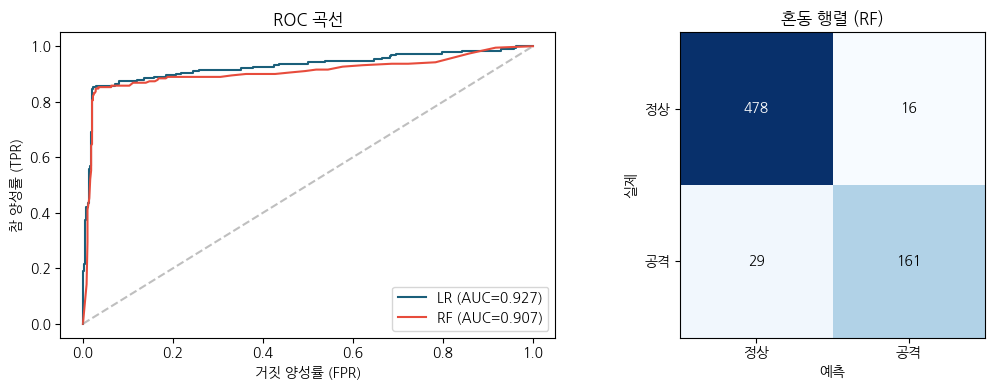

In [8]:
# ROC 곡선 + 혼동행렬 — 완벽하지 않은(현실적인) 탐지기의 성능
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc, confusion_matrix
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, pipe, color in [('LR', pipe_lr, '#1a5f7a'), ('RF', pipe_rf, '#e74c3c')]:
    pr = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, pr)
    ax1.plot(fpr, tpr, color=color, label=f'{name} (AUC={auc(fpr, tpr):.3f})')
ax1.plot([0, 1], [0, 1], '--', color='gray', alpha=0.5)
ax1.set_xlabel('거짓 양성률 (FPR)'); ax1.set_ylabel('참 양성률 (TPR)')
ax1.set_title('ROC 곡선'); ax1.legend(loc='lower right')
cm = confusion_matrix(y_test, pipe_rf.predict(X_test))
ax2.imshow(cm, cmap='Blues')
ax2.set_xticks([0, 1]); ax2.set_xticklabels(['정상', '공격'])
ax2.set_yticks([0, 1]); ax2.set_yticklabels(['정상', '공격'])
ax2.set_xlabel('예측'); ax2.set_ylabel('실제'); ax2.set_title('혼동 행렬 (RF)')
for (r, cc), v in np.ndenumerate(cm):
    ax2.text(cc, r, str(v), ha='center', va='center',
             color='white' if v > cm.max()/2 else 'black')
plt.tight_layout(); plt.show()

---
## Step 5. 우회 페이로드 강건성 테스트

In [9]:
evasion_examples = [
    ("/login?id=1' OR 1=1--", 'baseline SQLi'),
    ("/login?id=1%27%20OR%201%3D1", 'URL-encoded SQLi'),
    ("/login?id=1' OR/**/1=1", 'inline comment SQLi'),
    ("/login?id=1' Or 1=1", 'mixed case SQLi'),
    ("/search?q=<ScRiPt>alert(1)</ScRiPt>", 'mixed case XSS'),
    ("/search?q=%3Cimg+src=x+onerror=alert(1)%3E", 'URL-encoded XSS'),
]
test = pd.DataFrame(evasion_examples, columns=['raw', 'kind'])
test['norm'] = test['raw'].apply(normalize)
test['prob'] = pipe_rf.predict_proba(test['norm'])[:, 1].round(3)
test

,raw,kind,norm,prob
0,/login?id=1' OR 1=1--,baseline SQLi,/login?id=1' or 1=1--,0.800
1,/login?id=1%27%20OR%201%3D1,URL-encoded SQLi,/login?id=1' or 1=1,0.725
2,/login?id=1' OR/**/1=1,inline comment SQLi,/login?id=1' or/**/1=1,0.655
3,/login?id=1' Or 1=1,mixed case SQLi,/login?id=1' or 1=1,0.725
4,/search?q=<ScRiPt>alert(1)</ScRiPt>,mixed case XSS,/search?q=<script>alert(1)</script>,0.710
5,/search?q=%3Cimg+src=x+onerror=alert(1)%3E,URL-encoded XSS,/search?q=<img+src=x+onerror=alert(1)>,0.480


---
## 정리
- char-ngram TF-IDF 가 보안 텍스트 분류의 표준 기준 모델.
- URL 디코딩 후 모델에 입력하면 인코딩 우회가 무력화.
- RF 가 LR 보다 약간 더 robust 한 경우 많음.